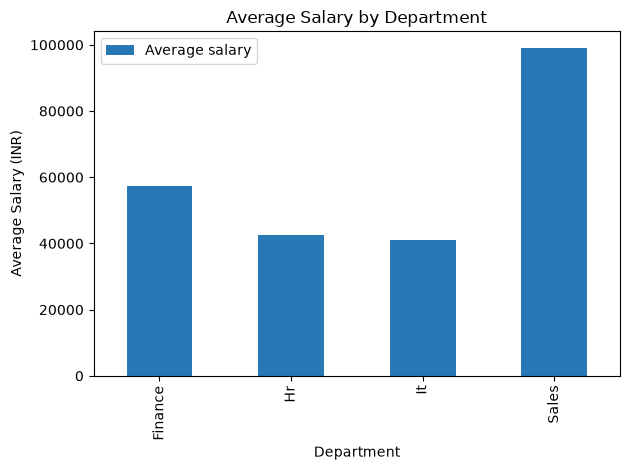

Insight: Sales has the highest average salary.


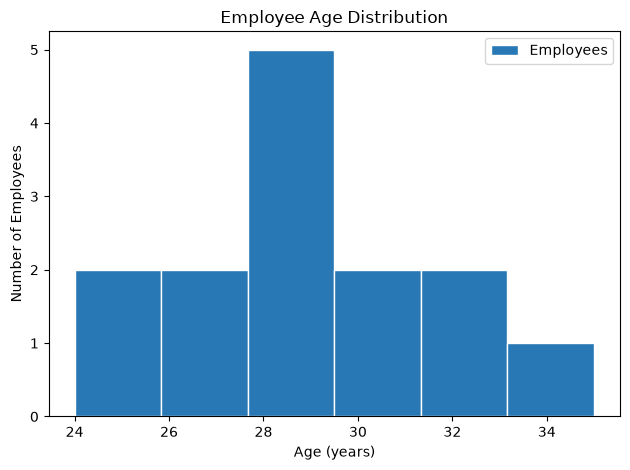

Insight: Most employees are in their twenties or early thirties.


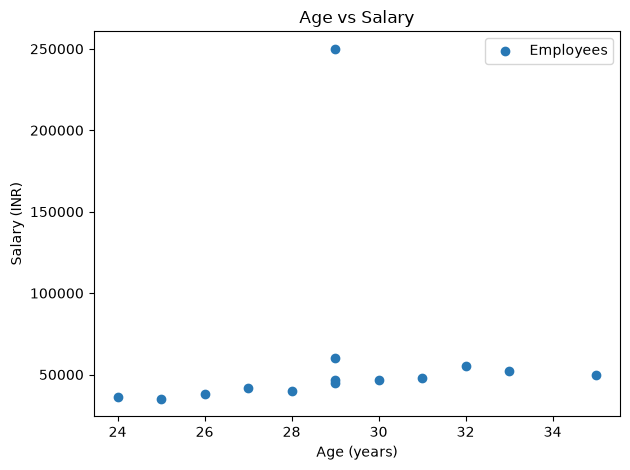

Insight: One employee has a much higher salary than the others.


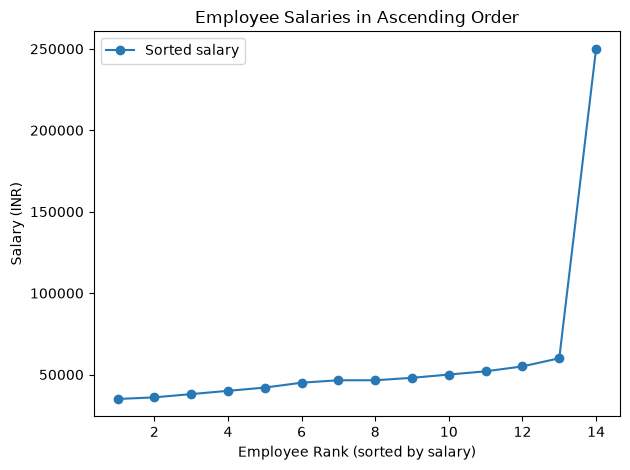

Insight: Most salaries are below INR 60,000.


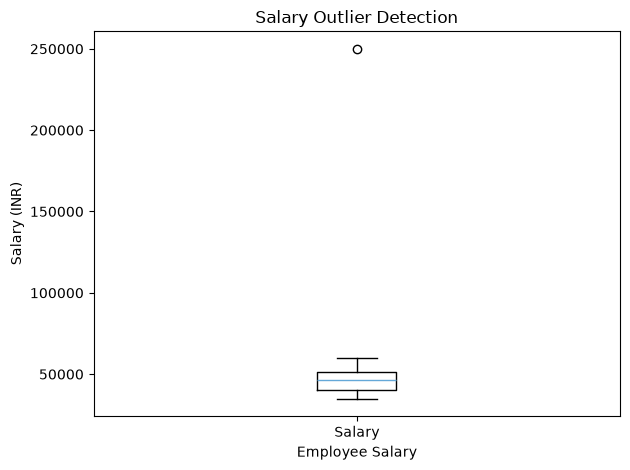

Insight: One unusually high salary is visible.


In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_csv("clean_data.csv")
df["joining_date"] = pd.to_datetime(df["joining_date"])

# Save all figures in reports/figures/
figures = Path("reports/figures")
figures.mkdir(parents=True, exist_ok=True)

plt.rcParams["axes.prop_cycle"] = plt.cycler(
    color=["#2878B5", "#64A8D8", "#A6CBE5"]
)

def save_chart(filename):
    plt.tight_layout()
    plt.savefig(figures / filename, dpi=150)
    plt.show()
    plt.close()

# 1. Bar chart
df.groupby("department")["salary"].mean().plot(
    kind="bar", color="#2878B5", label="Average salary"
)
plt.title("Average Salary by Department")
plt.xlabel("Department")
plt.ylabel("Average Salary (INR)")
plt.legend()
save_chart("bar_chart.png")
print("Insight: Sales has the highest average salary.")

# 2. Histogram
plt.hist(df["age"], bins=6, color="#2878B5",
         edgecolor="white", label="Employees")
plt.title("Employee Age Distribution")
plt.xlabel("Age (years)")
plt.ylabel("Number of Employees")
plt.legend()
save_chart("histogram.png")
print("Insight: Most employees are in their twenties or early thirties.")

# 3. Scatter plot
plt.scatter(df["age"], df["salary"],
            color="#2878B5", label="Employees")
plt.title("Age vs Salary")
plt.xlabel("Age (years)")
plt.ylabel("Salary (INR)")
plt.legend()
save_chart("scatter_plot.png")
print("Insight: One employee has a much higher salary than the others.")

# 4. Line chart - sorted values
sorted_salary = df["salary"].sort_values().reset_index(drop=True)
plt.plot(range(1, len(sorted_salary) + 1),
         sorted_salary, color="#2878B5",
         marker="o", label="Sorted salary")
plt.title("Employee Salaries in Ascending Order")
plt.xlabel("Employee Rank (sorted by salary)")
plt.ylabel("Salary (INR)")
plt.legend()
save_chart("line_chart.png")
print("Insight: Most salaries are below INR 60,000.")

# 5. Box plot
plt.boxplot(df["salary"], tick_labels=["Salary"])
plt.title("Salary Outlier Detection")
plt.xlabel("Employee Salary")
plt.ylabel("Salary (INR)")
save_chart("box_plot.png")
print("Insight: One unusually high salary is visible.")
